# Fase 3 – Preparação dos Dados (Data Preparation)

> **CRISP-DM:** construir, a partir dos dados iniciais, o(s) dataset(s) final(ais) que serão usados na modelação. Inclui a seleção de dados (3.1), a limpeza (3.2), a construção de novos atributos e registos (3.3), a integração e agregação de tabelas (3.4) e a formatação para as ferramentas de modelação (3.5). Outputs: *Dataset* e *Dataset Description*.

Nesta fase, ao contrário da Fase 2, os dados são **corrigidos e transformados**. As correções seguem os problemas identificados no Relatório de Qualidade dos Dados (2.4). Os ficheiros originais nunca são alterados: todas as operações são feitas em cópias, e os datasets finais são gravados como ficheiros novos.

**Datasets a produzir (um por objetivo de data mining)**

| Dataset | Objetivo | Unidade (1 linha =) | Variável alvo |
|---|---|---|---|
| D1 | DM1 – Classificação das patologias | episódio-dia com sinais vitais | patologias desse dia (multi-label) |
| D2 | DM2 – Regressão da duração do internamento | episódio-dia com sinais vitais | nº de dias que faltam até à alta |
| D3 | DM3 – Clustering de episódios | episódio | — (sem variável alvo) |

**Pressupostos**

Algumas decisões dependem de respostas do docente que ainda não foram obtidas. Até lá, assumem-se os seguintes pressupostos, que poderão ser revistos:

| # | Pressuposto | Justificação | Onde é usado |
|---|---|---|---|
| P1 | A duração do internamento é o nº de dias distintos com sinais vitais de cada episódio | Indicação do docente | 3.3, D2 |
| P2 | Só os episódio-dia com sinais vitais entram no D1; as patologias registadas em dias sem sinais vitais não são usadas como etiquetas diárias | Sem sinais vitais não há variáveis de entrada para esse dia | 3.1, D1 |
| P3 | Um episódio-dia com sinais vitais e sem patologia registada é tratado como "sem patologia" | Não existe outra forma de representar estes dias; a confirmar com o docente | 3.3, D1 |
| P4 | Os valores dos sinais vitais fora do domínio (999, 99, negativos, 0, etc.) são tratados como valores em falta | Não são medições possíveis (2.4.6) | 3.2 |
| P5 | Os 13 episódios que começam ou terminam nos limites do período dos dados são mantidos, com uma variável que os identifica | Excluí-los reduziria muito o nº de episódios (47); a variável permite avaliar o seu efeito na modelação | 3.1, 3.3 |
| P6 | Na regressão prevê-se, em cada episódio-dia, o nº de dias que faltam até à alta (duração do internamento menos o dia atual), usando apenas os dados desse dia e dos anteriores. As linhas do 1.º dia correspondem à previsão da duração à entrada. Os episódios que terminam no último dia do período não entram no treino da regressão, porque a sua alta é desconhecida | Antecipar a duração (O1) diariamente, aproveitando todos os episódio-dia (cerca de 450 em vez de 47 episódios) e sem dar ao modelo informação do futuro (fuga de informação) | 3.1, 3.3, D2 |
| P7 | As patologias que não aparecem nos dados não são consideradas; o tratamento das patologias raras é decidido na 3.1 | Não é possível aprender uma classe sem exemplos | 3.1 |
| P8 | As variáveis de entrada de cada episódio-dia (D1 e D2) usam apenas dados desse dia e dos dias anteriores do mesmo episódio; as patologias de dias anteriores não são usadas como variáveis de entrada | Evita usar informação do futuro (fuga de informação) e garante que o modelo deteta as patologias a partir dos sinais vitais, e não por copiar o dia anterior | 3.3, D1, D2 |

## 3.1 Seleção dos Dados (Select Data)
> **CRISP-DM:** decidir que dados são usados na análise, com base na relevância para os objetivos de data mining, na qualidade e em restrições técnicas. A seleção abrange atributos (colunas) e registos (linhas). Output: *Rationale for inclusion/exclusion*, com a lista dos dados incluídos e excluídos e as razões dessas decisões.

As decisões desta secção baseiam-se nos resultados da Fase 2. A seleção de registos que depende de códigos, datas ou nomes corrigidos é aplicada depois da limpeza (3.2); aqui fica definida e justificada.

In [2]:
# =============================================================================
# 3.1.1 Bibliotecas, estilo dos gráficos e carregamento dos dados
# Mesmas bibliotecas, paleta de cores e estilo do notebook da Fase 2, para
# que os gráficos das duas fases tenham o mesmo aspeto.
# Os dois ficheiros são lidos tal como foram fornecidos (df_sinais_orig e
# df_patologias_orig). Estas tabelas nunca são alteradas: todas as operações
# da Fase 3 são feitas em cópias.
# =============================================================================
import os
import re
import unicodedata
import difflib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# Paleta de cores (igual à da Fase 2)
AZUL, AZUL_CLARO, VERMELHO, LARANJA, CINZA = "#2F5496", "#DCE6F2", "#C00000", "#F4B183", "#555555"

sns.set_theme(style="whitegrid", rc={
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#EEEEEE", "figure.dpi": 100,
})

PASTA_DADOS = "dados/"
FICH_SINAIS = "sinais_vitais_por_hora.csv"
FICH_PATOLOGIAS = "patologias_por_dia.csv"

df_sinais_orig = pd.read_csv(os.path.join(PASTA_DADOS, FICH_SINAIS))
df_patologias_orig = pd.read_csv(os.path.join(PASTA_DADOS, FICH_PATOLOGIAS))

print(f"Sinais vitais: {df_sinais_orig.shape[0]} linhas × {df_sinais_orig.shape[1]} colunas")
print(f"Patologias:    {df_patologias_orig.shape[0]} linhas × {df_patologias_orig.shape[1]} colunas")

Sinais vitais: 9857 linhas × 6 colunas
Patologias:    696 linhas × 3 colunas


In [3]:
# =============================================================================
# 3.1.2 Funções de normalização e listas de referência
# Funções usadas na seleção (3.1) e na limpeza (3.2). Seguem as regras
# definidas e validadas na tarefa 2.4 (Verificação da Qualidade dos Dados):
# - normalizar_codigo:    ' ep018', 'EP 016' -> 'EP018', 'EP016' (2.4.3)
# - corrigir_data:        'AAAA-MM-DD' válida ou 'DD/MM/AAAA' -> data;
#                         datas impossíveis (2024-13-02, 31/02) -> NaT (2.4.4)
# - normalizar_patologia: variantes ('DMH', 'Sepsis', 'ANEMIA'…) -> nome
#                         oficial (2.4.7)
# Também se definem os nomes das colunas dos sinais vitais e a lista oficial
# das 13 patologias.
# =============================================================================
VITAIS = ["sat_o2", "puls_rate", "perfusion"]
OFICIAIS = ["Doença das membranas hialinas", "Icterícia neonatal", "Anemia", "Citomegalovírus",
            "Displasia broncopulmonar", "Persistência do canal arterial", "Refluxo gastroesofágico",
            "Sépsis", "Lesão renal aguda", "Retinopatia da prematuridade",
            "Hemorragia peri-intraventricular", "Enterocolite necrosante",
            "Doença metabólica óssea da prematuridade"]

def normalizar_codigo(codigo):
    """Código no formato EPnnn, ou None se não for reconhecível."""
    limpo = re.sub(r"[^A-Z0-9]", "", str(codigo).upper())
    m = re.fullmatch(r"(?:EP|E|P)?(\d{1,3})", limpo)
    return f"EP{int(m.group(1)):03d}" if m else None

def corrigir_data(texto):
    """Data a partir de 'AAAA-MM-DD' ou 'DD/MM/AAAA'; NaT se não for recuperável."""
    s = str(texto).strip()
    m = re.fullmatch(r"(\d{1,2})/(\d{1,2})/(\d{4})", s)
    if m:
        d, mes, a = m.groups()
        s = f"{a}-{int(mes):02d}-{int(d):02d}"
    return pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")

def simples(texto):
    """Minúsculas, sem acentos e com espaços simples (só para comparar)."""
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(t.lower().split())

OFICIAIS_SIMPLES = {simples(o): o for o in OFICIAIS}
ABREVIATURAS = {"dmh": "doenca das membranas hialinas", "cmv": "citomegalovirus",
                "pca": "persistencia do canal arterial", "rge": "refluxo gastroesofagico",
                "dbp": "displasia broncopulmonar", "rop": "retinopatia da prematuridade",
                "lra": "lesao renal aguda", "ecn": "enterocolite necrosante",
                "nec": "enterocolite necrosante", "hpiv": "hemorragia peri-intraventricular"}

def normalizar_patologia(valor):
    """Nome oficial da patologia, ou None se estiver em falta ou não for reconhecível."""
    if pd.isna(valor) or not str(valor).strip():
        return None
    s = simples(valor)
    if s in OFICIAIS_SIMPLES:                                    # espaços, maiúsculas, acentos
        return OFICIAIS_SIMPLES[s]
    abrev = ABREVIATURAS.get(s.replace(".", ""))
    if abrev in OFICIAIS_SIMPLES:                                # abreviaturas
        return OFICIAIS_SIMPLES[abrev]
    comecam = [o for k, o in OFICIAIS_SIMPLES.items() if k.startswith(s + " ")]
    if len(comecam) == 1:                                        # nome incompleto
        return comecam[0]
    parecido = difflib.get_close_matches(s, OFICIAIS_SIMPLES.keys(), n=1, cutoff=0.8)
    return OFICIAIS_SIMPLES[parecido[0]] if parecido else None   # gralha

# Verificação rápida das funções
print([normalizar_codigo(c) for c in [" ep018", "EP 016", "EP001"]])
print([str(corrigir_data(d))[:10] for d in ["2024-02-10", "10/02/2024", "2024-13-02", "2024-02-31"]])
print([normalizar_patologia(p) for p in ["DMH", "Sepsis", "ANEMIA ", "icterícia", "Doenca das membranas hialinas"]])

['EP018', 'EP016', 'EP001']
['2024-02-10', '2024-02-10', 'NaT', 'NaT']
['Doença das membranas hialinas', 'Sépsis', 'Anemia', 'Icterícia neonatal', 'Doença das membranas hialinas']


,episódio-dia (todos),episódio-dia com sinais vitais,episódios (todos),episódios com sinais vitais,decisão
patologia,,,,,
Doença das membranas hialinas,282,236,28,26,modelar
Icterícia neonatal,161,117,21,20,modelar
Anemia,56,43,7,6,modelar
Citomegalovírus,49,32,7,6,modelar
Persistência do canal arterial,31,30,3,3,modelar
Displasia broncopulmonar,38,37,2,2,modelar
Sépsis,18,12,3,2,modelar
Refluxo gastroesofágico,27,23,2,1,manter no dataset
Lesão renal aguda,3,2,1,1,manter no dataset


modelar (7): ['Doença das membranas hialinas', 'Icterícia neonatal', 'Anemia', 'Citomegalovírus', 'Persistência do canal arterial', 'Displasia broncopulmonar', 'Sépsis']
manter no dataset (2): ['Refluxo gastroesofágico', 'Lesão renal aguda']
excluir (4): ['Retinopatia da prematuridade', 'Hemorragia peri-intraventricular', 'Enterocolite necrosante', 'Doença metabólica óssea da prematuridade']


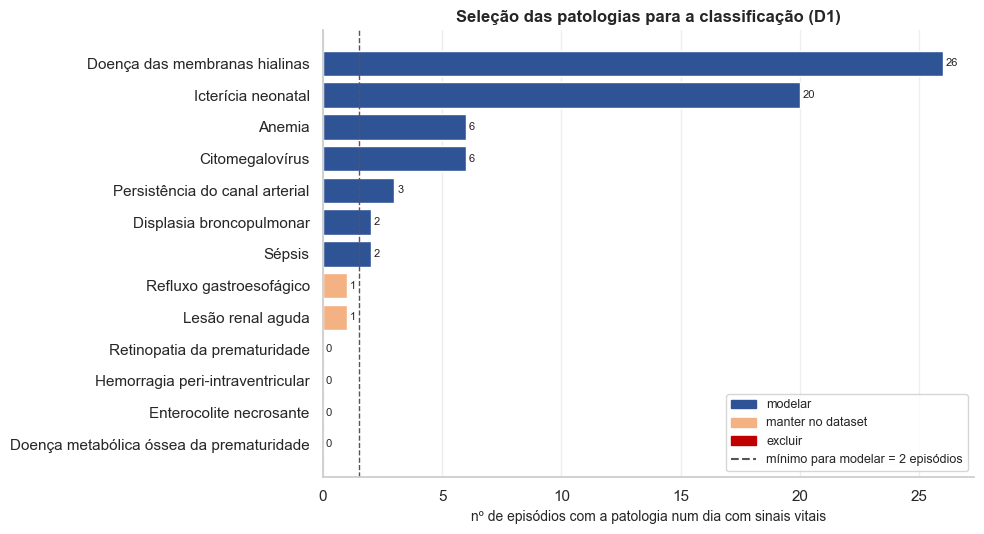

In [4]:
# =============================================================================
# 3.1.3 Seleção das patologias (P7)
# Uma patologia só pode ser modelada no D1 (classificação) se houver
# exemplos suficientes para o modelo aprender e ser avaliado. Como treino e
# teste vão ser separados por episódio (os dias do mesmo bebé são muito
# parecidos), o critério é o nº de EPISÓDIOS com a patologia num dia com
# sinais vitais (P2), e não o nº de registos.
# Critério (três níveis):
# - modelar: aparece em pelo menos MIN_EPISODIOS episódios com sinais vitais
#   (mínimo para poder estar no treino e no teste ao mesmo tempo)
# - manter no dataset: aparece em 1 episódio com sinais vitais; fica como
#   coluna do D1 (não se perde informação), mas não é modelada
# - excluir: não aparece em nenhum dia com sinais vitais
# Contagem feita numa vista temporária com códigos, datas e nomes
# normalizados (funções da 3.1.2) e sem linhas repetidas.
# =============================================================================
MIN_EPISODIOS = 2

# Episódio-dia com sinais vitais
dias_sinais = set(zip(df_sinais_orig["episodio"].map(normalizar_codigo),
                      df_sinais_orig["data"].map(corrigir_data)))

vista_p = pd.DataFrame({"episodio": df_patologias_orig["episodio"].map(normalizar_codigo),
                        "data": df_patologias_orig["data"].map(corrigir_data),
                        "patologia": df_patologias_orig["patologia"].map(normalizar_patologia)})
vista_p = vista_p.dropna().drop_duplicates()
vista_p["tem sinais vitais"] = [(e, d) in dias_sinais for e, d in zip(vista_p["episodio"], vista_p["data"])]
com_sv = vista_p[vista_p["tem sinais vitais"]]

sel_pat = pd.DataFrame({
    "episódio-dia (todos)": vista_p.groupby("patologia").size(),
    "episódio-dia com sinais vitais": com_sv.groupby("patologia").size(),
    "episódios (todos)": vista_p.groupby("patologia")["episodio"].nunique(),
    "episódios com sinais vitais": com_sv.groupby("patologia")["episodio"].nunique(),
}).reindex(OFICIAIS).fillna(0).astype(int)
n_ep = sel_pat["episódios com sinais vitais"]
sel_pat["decisão"] = np.select([n_ep >= MIN_EPISODIOS, n_ep >= 1],
                               ["modelar", "manter no dataset"], "excluir")
sel_pat = sel_pat.sort_values(["episódios com sinais vitais", "episódio-dia com sinais vitais"], ascending=False)
display(sel_pat)

PATOLOGIAS_D1 = sel_pat.index[sel_pat["decisão"] != "excluir"].tolist()        # colunas do D1
PATOLOGIAS_MODELO = sel_pat.index[sel_pat["decisão"] == "modelar"].tolist()    # modeladas na Fase 4
for decisao in ["modelar", "manter no dataset", "excluir"]:
    lista = sel_pat.index[sel_pat["decisão"] == decisao].tolist()
    print(f"{decisao} ({len(lista)}): {lista}")

# --- Gráfico: nº de episódios com cada patologia (em dias com sinais vitais)
fig, ax = plt.subplots(figsize=(10, 5.5))
cores = sel_pat["decisão"].map({"modelar": AZUL, "manter no dataset": LARANJA, "excluir": VERMELHO})
barras = ax.barh(sel_pat.index, sel_pat["episódios com sinais vitais"], color=cores)
ax.bar_label(barras, fontsize=8, padding=2)
ax.axvline(MIN_EPISODIOS - 0.5, color=CINZA, ls="--", lw=1)
ax.invert_yaxis()
ax.set_xlabel("nº de episódios com a patologia num dia com sinais vitais")
ax.set_title("Seleção das patologias para a classificação (D1)")
ax.legend(handles=[Patch(color=AZUL, label="modelar"), Patch(color=LARANJA, label="manter no dataset"),
                   Patch(color=VERMELHO, label="excluir"),
                   Line2D([], [], color=CINZA, ls="--", label=f"mínimo para modelar = {MIN_EPISODIOS} episódios")],
          loc="lower right", fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [5]:

# =============================================================================
# 3.1.4 Seleção dos episódios (P5 e P6)
# Todos os episódios com sinais vitais são mantidos. Para cada um calcula-se,
# numa vista temporária com códigos e datas corrigidos (3.1.2):
# - primeiro e último dia com sinais vitais e nº de dias (P1)
# - se começa no primeiro dia do período dos dados (pode ter começado antes)
# - se termina no último dia do período (a alta é desconhecida)
# e em que datasets entra:
# - D1 (classificação) e D3 (clustering): todos os episódios (P5)
# - D2 (regressão): no treino só entram episódios com alta conhecida, ou
#   seja, que não terminam no último dia do período (P6)
# Os dados não são alterados.
# =============================================================================
vista_s = pd.DataFrame({"episodio": df_sinais_orig["episodio"].map(normalizar_codigo),
                        "data": df_sinais_orig["data"].map(corrigir_data)}).dropna()
inicio_periodo, fim_periodo = vista_s["data"].min(), vista_s["data"].max()

episodios = vista_s.groupby("episodio")["data"].agg(primeiro_dia="min", ultimo_dia="max", dias_com_sinais="nunique")
episodios["comeca_no_limite"] = episodios["primeiro_dia"] == inicio_periodo
episodios["termina_no_limite"] = episodios["ultimo_dia"] == fim_periodo
episodios["tem_patologia"] = episodios.index.isin(vista_p["episodio"])
episodios["D2_treino"] = ~episodios["termina_no_limite"]

print(f"Período dos dados: {inicio_periodo:%d/%m/%Y} a {fim_periodo:%d/%m/%Y}")
print(f"Episódios: {len(episodios)} | começam no limite: {episodios['comeca_no_limite'].sum()} | "
      f"terminam no limite: {episodios['termina_no_limite'].sum()} | "
      f"nos dois: {(episodios['comeca_no_limite'] & episodios['termina_no_limite']).sum()}")
print(f"Episódios sem patologia registada: {(~episodios['tem_patologia']).sum()}")

resumo_ds = pd.DataFrame({
    "episódios": [len(episodios), episodios["D2_treino"].sum(), len(episodios)],
    "episódio-dia com sinais vitais": [episodios["dias_com_sinais"].sum(),
                                       episodios.loc[episodios["D2_treino"], "dias_com_sinais"].sum(),
                                       "—"]},
    index=["D1 – classificação", "D2 – regressão (treino)", "D3 – clustering"])
display(resumo_ds)

print("Episódios que terminam no limite (fora do treino do D2):")
display(episodios[episodios["termina_no_limite"]].assign(
    primeiro_dia=lambda t: t["primeiro_dia"].dt.strftime("%d/%m"),
    ultimo_dia=lambda t: t["ultimo_dia"].dt.strftime("%d/%m")))

Período dos dados: 30/01/2024 a 20/04/2024
Episódios: 47 | começam no limite: 3 | terminam no limite: 10 | nos dois: 0
Episódios sem patologia registada: 8


,episódios,episódio-dia com sinais vitais
D1 – classificação,47,449
D2 – regressão (treino),37,336
D3 – clustering,47,—


Episódios que terminam no limite (fora do treino do D2):


,primeiro_dia,ultimo_dia,dias_com_sinais,comeca_no_limite,termina_no_limite,tem_patologia,D2_treino
episodio,,,,,,,
EP026,16/03,20/04,36,False,True,True,False
EP034,03/04,20/04,18,False,True,True,False
EP036,08/04,20/04,13,False,True,True,False
EP039,11/04,20/04,10,False,True,True,False
EP040,11/04,20/04,10,False,True,True,False
EP042,13/04,20/04,8,False,True,True,False
EP044,15/04,20/04,6,False,True,False,False
EP045,15/04,20/04,6,False,True,True,False
EP046,17/04,20/04,4,False,True,True,False


### Relatório de Seleção dos Dados (Rationale for Inclusion/Exclusion)

**Atributos (colunas)**

| Tabela | Atributo | Decisão | Justificação |
|---|---|---|---|
| Sinais vitais | `episodio` | Incluído como identificador | Liga as duas tabelas e agrupa os registos por episódio. Não é usado como variável de entrada dos modelos, porque o modelo aprenderia o bebé e não a patologia (H8); é usado para separar treino e teste por episódio |
| Sinais vitais | `data` | Incluído como chave | Define o episódio-dia, a unidade do D1 e do D2, e permite calcular o dia do episódio e a duração (P1) |
| Sinais vitais | `hora` | Incluída para ordenar e agregar | Permite ordenar os registos e agregá-los por dia. A hora do dia tem pouca influência nos sinais vitais (H6), pelo que não é usada diretamente como variável de entrada |
| Sinais vitais | `sat_o2`, `puls_rate`, `perfusion` | Incluídos | São as variáveis de entrada dos modelos; os três são pouco correlacionados entre si e trazem informação própria (H7) |
| Patologias | `episodio`, `data` | Incluídos como chave | Ligam cada patologia a um episódio-dia |
| Patologias | `patologia` | Incluída | Variável alvo do D1 (classificação) e parte do perfil do episódio no D3 (clustering) |

**Patologias (3.1.3)**

Como treino e teste vão ser separados por episódio, uma patologia só pode ser modelada se aparecer em pelo menos 2 episódios com sinais vitais nesse dia: o mínimo para poder estar no treino e no teste ao mesmo tempo.

| Decisão | Patologias | Justificação |
|---|---|---|
| Modelar (7) | Doença das membranas hialinas (26 episódios), icterícia neonatal (20), anemia (6), citomegalovírus (6), persistência do canal arterial (3), displasia broncopulmonar (2), sépsis (2) | Exemplos suficientes para treinar e avaliar |
| Manter no dataset, sem modelar (2) | Refluxo gastroesofágico (1), lesão renal aguda (1) | Só aparecem num episódio com sinais vitais: não é possível treinar e avaliar um modelo com um único bebé. Ficam como colunas do D1, para não se perder informação |
| Excluir do D1 (4) | Retinopatia da prematuridade, hemorragia peri-intraventricular, enterocolite necrosante, doença metabólica óssea da prematuridade | A retinopatia só aparece em dias sem sinais vitais (continua a contar no perfil do episódio do D3); as outras três não aparecem nos dados |

A sépsis, considerada prioritária na Business Understanding (critério C2), é modelada, mas com apenas 2 episódios e 12 dias, pelo que os seus resultados terão pouca robustez. A enterocolite necrosante, a outra patologia prioritária, não pode ser modelada por não existir nos dados.

**Registos (linhas)**

| Registos | Decisão | Justificação |
|---|---|---|
| Patologias em dias sem sinais vitais (135 de 667 episódio-dia com patologia, 20 %) | Excluídos do D1; incluídos no perfil do episódio do D3 | Sem sinais vitais não há variáveis de entrada para esse dia (P2) |
| Episódio-dia com sinais vitais e sem patologia registada | Incluídos no D1 como "sem patologia" | Pressuposto P3, a confirmar com o docente |
| 8 episódios sem nenhuma patologia (EP007, EP012, EP021, EP028, EP031, EP035, EP044, EP047) | Incluídos | Representam bebés sem patologia registada (P3) e são necessários como casos negativos |
| 3 episódios que começam no primeiro dia do período | Incluídos em todos os datasets, identificados pela variável `comeca_no_limite` | Os dias que faltam até à alta são conhecidos. O dia do episódio e a duração total estão subestimados, pelo que estes episódios não entram na avaliação da previsão à entrada |
| 10 episódios que terminam no último dia do período (EP026, EP034, EP036, EP039, EP040, EP042, EP044, EP045, EP046, EP047) | Incluídos no D1 e no D3; excluídos do treino do D2 | A data da alta é desconhecida, pelo que a variável alvo da regressão também o é (P6) |
| Registos com problemas de qualidade (duplicados, datas impossíveis, valores fora do domínio, etc.) | Tratados na limpeza (3.2) | Ver Relatório de Limpeza dos Dados |

**Resumo dos datasets**

| Dataset | Episódios | Episódio-dia com sinais vitais | Variável alvo |
|---|---|---|---|
| D1 – Classificação | 47 | 449 | 9 patologias (7 modeladas) |
| D2 – Regressão (treino) | 37 | 336 | Dias que faltam até à alta |
| D3 – Clustering | 47 | — (1 linha por episódio) | — |

**Limitações da seleção**

- **D2:** a exclusão dos episódios que terminam no limite (censura à direita) retira 25 % dos episódio-dia e sobretudo internamentos longos, como o EP026 (36 dias). O modelo de regressão poderá subestimar a duração dos internamentos mais longos.
- **D1:** quatro das sete patologias modeladas têm 6 ou menos episódios, e a sépsis e a displasia apenas 2. Os resultados para estas patologias serão pouco robustos.
- **Pressupostos:** as decisões dependem dos pressupostos P2, P3 e P6, que serão revistos com a resposta do docente.

## 3.2 Limpeza dos Dados (Clean Data)
> **CRISP-DM:** elevar a qualidade dos dados ao nível exigido pelas técnicas de análise selecionadas. Pode envolver a seleção de subconjuntos limpos, a inserção de valores por defeito ou técnicas mais avançadas, como a estimação de valores em falta. Output: *Data Cleaning Report*, com as decisões e ações tomadas para resolver os problemas identificados na Verificação da Qualidade dos Dados (2.4) e o seu possível impacto nos resultados.

As correções seguem o quadro-resumo do Relatório de Qualidade dos Dados (2.4), pela seguinte ordem:
1. códigos de episódio;
2. datas;
3. horas;
4. registos duplicados;
5. valores dos sinais vitais (decimais com vírgula e valores fora do domínio);
6. nomes de patologia e linhas sem patologia.

Os códigos, as datas e as horas são corrigidos primeiro, porque são a chave dos registos: só depois é possível identificar corretamente os duplicados. Todas as correções são feitas em cópias de trabalho (`df_sinais` e `df_patologias`); as tabelas originais não são alteradas.

In [6]:
# =============================================================================
# 3.2.1 Cópias de trabalho e correção dos códigos de episódio
# Criam-se as tabelas de trabalho df_sinais e df_patologias, cópias das
# originais (que nunca são alteradas). Todas as correções da 3.2 são feitas
# nestas cópias.
# Cria-se também o registo_limpeza, onde cada passo da limpeza guarda o que
# fez e a quantos registos; no fim (3.2.7) dá o resumo para o relatório.
# Passo 1 – códigos de episódio (2.4.3): retirar espaços e passar a
# maiúsculas, com normalizar_codigo (3.1.2). Ex.: ' ep018' -> 'EP018'.
# =============================================================================
df_sinais = df_sinais_orig.copy()
df_patologias = df_patologias_orig.copy()
TABELAS = {"sinais vitais": df_sinais, "patologias": df_patologias}

registo_limpeza = []
def registar(tabela, passo, acao, n_registos):
    """Guarda uma ação de limpeza e o nº de linhas da tabela depois dela."""
    registo_limpeza.append({"tabela": tabela, "passo": passo, "ação": acao,
                            "registos afetados": int(n_registos), "linhas depois": len(TABELAS[tabela])})

for nome, df in TABELAS.items():
    original = df["episodio"].copy()
    df["episodio"] = original.map(normalizar_codigo)
    alterados = original != df["episodio"]

    print(f"=== {nome}: {alterados.sum()} códigos corrigidos ===")
    display(pd.DataFrame({"código original": original[alterados].map(repr),
                          "código corrigido": df.loc[alterados, "episodio"]})
              .value_counts().rename("nº de registos").reset_index())
    formato_ok = df["episodio"].str.fullmatch(r"EP\d{3}").all()
    print(f"Códigos não reconhecidos: {df['episodio'].isna().sum()} | "
          f"todos no formato EPnnn: {formato_ok} | "
          f"episódios distintos: {df['episodio'].nunique()}\n")
    registar(nome, "1. Códigos de episódio", "Código corrigido (espaços/minúsculas)", alterados.sum())

=== sinais vitais: 12 códigos corrigidos ===


,código original,código corrigido,nº de registos
0,'ep018',EP018,2
1,' EP011',EP011,1
2,'EP 016',EP016,1
3,'ep019',EP019,1
4,'ep016',EP016,1
5,' EP016',EP016,1
6,'ep023',EP023,1
7,' EP027',EP027,1
8,'EP 034',EP034,1
9,'EP 036',EP036,1


Códigos não reconhecidos: 0 | todos no formato EPnnn: True | episódios distintos: 47

=== patologias: 6 códigos corrigidos ===


,código original,código corrigido,nº de registos
0,' EP009',EP009,1
1,'EP 018',EP018,1
2,'ep018',EP018,1
3,'ep029',EP029,1
4,' EP020',EP020,1
5,'EP 037',EP037,1


Códigos não reconhecidos: 0 | todos no formato EPnnn: True | episódios distintos: 39



In [7]:
# =============================================================================
# 3.2.2 Correção das datas
# Passo 2 – datas (2.4.4), com corrigir_data (3.1.2):
# - datas no formato DD/MM/AAAA são reescritas como AAAA-MM-DD
#   (todas caem num dia que já existe no mesmo episódio)
# - datas impossíveis (2024-13-02, 2024-02-30, 2024-02-31) não são
#   recuperáveis: não se sabe a que dia pertencem, e os registos são removidos
# A coluna data passa a ser do tipo data (datetime), o que permite ordenar e
# calcular diferenças entre dias nas tarefas seguintes.
# =============================================================================
for nome, df in TABELAS.items():
    original = df["data"].copy()
    nova = original.map(corrigir_data)
    ja_validas = pd.to_datetime(original, format="%Y-%m-%d", errors="coerce").notna()
    reescritas = ~ja_validas & nova.notna()
    impossiveis = nova.isna()

    print(f"=== {nome}: {reescritas.sum()} datas reescritas | {impossiveis.sum()} registos removidos ===")
    print("Datas reescritas (original -> corrigida):")
    display(pd.DataFrame({"data original": original[reescritas],
                          "data corrigida": nova[reescritas].dt.strftime("%Y-%m-%d")})
              .value_counts().rename("nº de registos").reset_index())
    print("Registos removidos (data impossível):")
    display(df[impossiveis])

    df["data"] = nova
    df.drop(index=df.index[impossiveis], inplace=True)
    registar(nome, "2. Datas", "Data reescrita (DD/MM/AAAA -> AAAA-MM-DD)", reescritas.sum())
    registar(nome, "2. Datas", "Registo removido (data impossível)", impossiveis.sum())
    print(f"Linhas: {len(original)} -> {len(df)} | tipo da coluna data: {df['data'].dtype}\n")

=== sinais vitais: 15 datas reescritas | 3 registos removidos ===
Datas reescritas (original -> corrigida):


,data original,data corrigida,nº de registos
0,10/02/2024,2024-02-10,2
1,18/04/2024,2024-04-18,2
2,31/01/2024,2024-01-31,1
3,05/02/2024,2024-02-05,1
4,14/02/2024,2024-02-14,1
5,09/03/2024,2024-03-09,1
6,13/03/2024,2024-03-13,1
7,18/03/2024,2024-03-18,1
8,20/03/2024,2024-03-20,1
9,21/03/2024,2024-03-21,1


Registos removidos (data impossível):


,episodio,data,hora,sat_o2,puls_rate,perfusion
3261,EP016,2024-02-31,9,99.11,167.54,0.73
4057,EP018,2024-13-02,19,94.18,150.51,1.22
9144,EP042,2024-13-02,19,94.58,158.53,1.27


Linhas: 9857 -> 9854 | tipo da coluna data: datetime64[us]

=== patologias: 8 datas reescritas | 2 registos removidos ===
Datas reescritas (original -> corrigida):


,data original,data corrigida,nº de registos
0,26/02/2024,2024-02-26,2
1,10/02/2024,2024-02-10,1
2,09/03/2024,2024-03-09,1
3,12/03/2024,2024-03-12,1
4,20/03/2024,2024-03-20,1
5,14/04/2024,2024-04-14,1
6,20/04/2024,2024-04-20,1


Registos removidos (data impossível):


,episodio,data,patologia
414,EP017,2024-13-02,Sépsis
511,EP025,2024-02-30,Citomegalovírus


Linhas: 696 -> 694 | tipo da coluna data: datetime64[us]



In [8]:
# =============================================================================
# 3.2.3 Correção das horas fora de 0–23
# Passo 3 – horas (2.4.5). Para cada registo com hora fora de 0–23
# (-1, 24, 25), olha-se para as horas que já existem nesse episódio-dia
# (com códigos e datas já corrigidos):
# - falta exatamente 1 hora -> o registo é essa hora mal escrita: atribui-se
#   a hora em falta
# - falta mais do que 1 hora (dias parciais, no início ou no fim do
#   episódio) -> não se sabe qual era a hora: o registo é removido
# - não falta nenhuma hora -> o registo está a mais: é removido
# No fim, a coluna hora passa a ser um número inteiro.
# =============================================================================
hora_num = pd.to_numeric(df_sinais["hora"], errors="coerce")
fora = ~hora_num.between(0, 23)
horas_dia = (df_sinais[~fora].assign(hora=hora_num[~fora])
             .groupby(["episodio", "data"])["hora"].agg(set))

linhas, remover = [], []
for i in df_sinais.index[fora]:
    e, d = df_sinais.at[i, "episodio"], df_sinais.at[i, "data"]
    em_falta = sorted(set(range(24)) - horas_dia.get((e, d), set()))
    if len(em_falta) == 1:
        hora_atribuida, decisao = em_falta[0], "hora atribuída"
        hora_num[i] = hora_atribuida
    else:
        hora_atribuida, decisao = None, "removido"
        remover.append(i)
    linhas.append({"episodio": e, "data": d.strftime("%Y-%m-%d"), "hora original": df_sinais.at[i, "hora"],
                   "nº de horas em falta no dia": len(em_falta), "decisão": decisao,
                   "hora atribuída": hora_atribuida})

print(f"Registos com hora fora de 0–23: {fora.sum()}")
display(pd.DataFrame(linhas).astype({"hora atribuída": "Int64"}))

df_sinais["hora"] = hora_num
df_sinais.drop(index=remover, inplace=True)
df_sinais["hora"] = df_sinais["hora"].astype(int)
registar("sinais vitais", "3. Horas", "Hora atribuída (única hora em falta no dia)", fora.sum() - len(remover))
registar("sinais vitais", "3. Horas", "Registo removido (hora impossível de determinar)", len(remover))

print(f"Linhas: {len(df_sinais)} | horas entre 0 e 23: {df_sinais['hora'].between(0, 23).all()} | "
      f"tipo da coluna hora: {df_sinais['hora'].dtype}")

Registos com hora fora de 0–23: 8


,episodio,data,hora original,nº de horas em falta no dia,decisão,hora atribuída
0,EP004,2024-02-11,-1,1,hora atribuída,17
1,EP006,2024-02-14,24,1,hora atribuída,7
2,EP004,2024-02-17,-1,1,hora atribuída,4
3,EP023,2024-03-09,-1,18,removido,<NA>
4,EP026,2024-03-29,-1,1,hora atribuída,5
5,EP031,2024-03-29,24,10,removido,<NA>
6,EP026,2024-04-16,25,1,hora atribuída,0
7,EP044,2024-04-20,-1,1,hora atribuída,4


Linhas: 9852 | horas entre 0 e 23: True | tipo da coluna hora: int64


In [9]:
# =============================================================================
# 3.2.4 Remoção dos registos duplicados
# Passo 4 – duplicados (2.4.2). Com os códigos, as datas e as horas já
# corrigidos, as linhas totalmente repetidas são removidas, mantendo a
# primeira ocorrência. Na 2.4.2 vimos que todas as repetições são exatas
# (sem valores contraditórios), pelo que não se perde informação.
# Verifica-se também se, depois das correções, ficou alguma chave repetida
# com valores diferentes (contradição):
#   sinais vitais: episodio + data + hora | patologias: episodio + data + patologia
# Nas patologias, os duplicados criados ao agrupar os nomes são tratados na
# 3.2.6, depois de normalizar os nomes.
# =============================================================================
CHAVES = {"sinais vitais": ["episodio", "data", "hora"], "patologias": ["episodio", "data", "patologia"]}

for nome, df in TABELAS.items():
    antes = len(df)
    repetidas = df.duplicated(keep="first")
    df.drop(index=df.index[repetidas], inplace=True)
    contraditorias = df.duplicated(subset=CHAVES[nome], keep=False)

    print(f"=== {nome} ===")
    print(f"Linhas totalmente repetidas removidas: {repetidas.sum()} | linhas: {antes} -> {len(df)}")
    print(f"Chaves repetidas com valores diferentes: {contraditorias.sum()}")
    if contraditorias.any():
        display(df[contraditorias].sort_values(CHAVES[nome]))
    registar(nome, "4. Duplicados", "Linha totalmente repetida removida", repetidas.sum())
    print()

=== sinais vitais ===
Linhas totalmente repetidas removidas: 60 | linhas: 9852 -> 9792
Chaves repetidas com valores diferentes: 0

=== patologias ===
Linhas totalmente repetidas removidas: 15 | linhas: 694 -> 679
Chaves repetidas com valores diferentes: 0



,vírgula -> ponto,não convertíveis,fora do domínio -> em falta,em falta (originais),em falta (total),% em falta,mínimo,máximo
sinal vital,,,,,,,,
sat_o2,3,0,27,44,71,0.73,82.19,100.00
puls_rate,7,0,20,64,84,0.86,94.81,187.63
perfusion,5,0,23,42,65,0.66,0.26,5.07


Tipos das colunas: {'sat_o2': dtype('float64'), 'puls_rate': dtype('float64'), 'perfusion': dtype('float64')}
Registos sem nenhum sinal vital: 0 | registos com algum valor em falta: 219


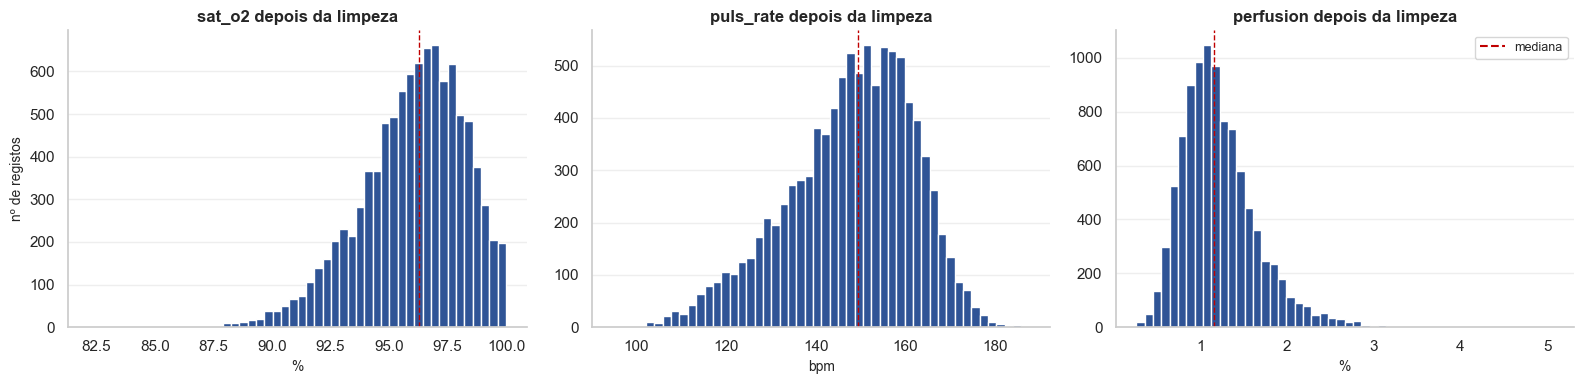

In [10]:
# =============================================================================
# 3.2.5 Correção dos valores dos sinais vitais
# Passo 5 – sinais vitais (2.4.6):
# - decimais com vírgula ('97,57') -> ponto ('97.57'); a coluna passa a numérica
# - valores fora do domínio (impossíveis) -> valor em falta (P4); só esse
#   valor é apagado, o registo mantém-se (os outros sinais estão corretos)
#     saturação ]0, 100] % | pulso [40, 300] bpm | perfusão ]0, 20] %
# - outliers plausíveis (IQR) e valores em falta originais mantêm-se.
#   Os valores em falta não são preenchidos aqui: a agregação diária (3.4)
#   calcula os resumos com as horas disponíveis.
# =============================================================================
DOMINIO = {"sat_o2": (0, 100), "puls_rate": (40, 300), "perfusion": (0, 20)}
EXCLUI_ZERO = {"sat_o2", "perfusion"}      # nestas variáveis um 0 significa "sem leitura"

linhas = []
for v in VITAIS:
    bruto = df_sinais[v]
    em_falta_orig = bruto.isna()
    texto = bruto.astype("string")
    com_virgula = texto.str.contains(",", regex=False).fillna(False)
    x = pd.to_numeric(texto.str.replace(",", ".", regex=False), errors="coerce").astype("float64")
    nao_convertidos = ~em_falta_orig & x.isna()                  # texto que não é número (deve ser 0)

    lo, hi = DOMINIO[v]
    abaixo = (x <= lo) if v in EXCLUI_ZERO else (x < lo)
    fora = abaixo | (x > hi)
    df_sinais[v] = x.mask(fora)

    linhas.append({"sinal vital": v, "vírgula -> ponto": com_virgula.sum(),
                   "não convertíveis": nao_convertidos.sum(), "fora do domínio -> em falta": fora.sum(),
                   "em falta (originais)": em_falta_orig.sum(), "em falta (total)": df_sinais[v].isna().sum(),
                   "% em falta": round(df_sinais[v].isna().mean() * 100, 2),
                   "mínimo": df_sinais[v].min(), "máximo": df_sinais[v].max()})
    registar("sinais vitais", "5. Sinais vitais", f"{v}: decimal com vírgula convertido", com_virgula.sum())
    registar("sinais vitais", "5. Sinais vitais", f"{v}: valor fora do domínio -> em falta", fora.sum())

display(pd.DataFrame(linhas).set_index("sinal vital"))
sem_nenhum = df_sinais[VITAIS].isna().all(axis=1)
print(f"Tipos das colunas: {df_sinais[VITAIS].dtypes.to_dict()}")
print(f"Registos sem nenhum sinal vital: {sem_nenhum.sum()} | "
      f"registos com algum valor em falta: {df_sinais[VITAIS].isna().any(axis=1).sum()}")

# --- Gráfico: distribuição de cada sinal vital depois da limpeza
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v in zip(axes, VITAIS):
    ax.hist(df_sinais[v].dropna(), bins=50, color=AZUL)
    ax.axvline(df_sinais[v].median(), color=VERMELHO, ls="--", lw=1)
    ax.set_title(f"{v} depois da limpeza")
    ax.set_xlabel({"sat_o2": "%", "puls_rate": "bpm", "perfusion": "%"}[v])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("nº de registos")
axes[2].legend(handles=[Line2D([], [], color=VERMELHO, ls="--", label="mediana")], fontsize=9)
plt.tight_layout()
plt.show()

In [11]:
# =============================================================================
# 3.2.6 Correção dos nomes de patologia e linhas sem patologia
# Passo 6 – patologias (2.4.1 e 2.4.7):
# - variantes ('DMH', 'Sepsis', 'ANEMIA', 'icterícia'…) -> nome oficial, com
#   normalizar_patologia (3.1.2)
# - linhas sem patologia (12) -> removidas: 8 estão em dias que já têm outra
#   patologia (sobras); nas outras 4, pelo P3 um dia sem patologia registada
#   é tratado como "sem patologia", pelo que a linha vazia não acrescenta
#   informação (o dia continua a existir nos sinais vitais)
# - depois de agrupar os nomes, removem-se as linhas que passaram a ser
#   repetidas (ex.: 'DMH' e 'Doença das membranas hialinas' no mesmo dia;
#   na 2.4.7 não havia nenhuma)
# =============================================================================
original = df_patologias["patologia"].copy()
df_patologias["patologia"] = original.map(normalizar_patologia)
corrigidos = original.notna() & (original != df_patologias["patologia"])
sem_patologia = df_patologias["patologia"].isna()
nao_reconhecidos = original.notna() & sem_patologia            # deve ser 0

print(f"Nomes corrigidos: {corrigidos.sum()} | não reconhecidos: {nao_reconhecidos.sum()} | "
      f"linhas sem patologia: {(original.isna()).sum()}")
display(pd.DataFrame({"nome original": original[corrigidos].map(repr),
                      "nome oficial": df_patologias.loc[corrigidos, "patologia"]})
          .value_counts().rename("nº de registos").reset_index()
          .sort_values(["nome oficial", "nº de registos"], ascending=[True, False]).reset_index(drop=True))
registar("patologias", "6. Patologias", "Nome corrigido para o nome oficial", corrigidos.sum())

df_patologias.drop(index=df_patologias.index[sem_patologia], inplace=True)
registar("patologias", "6. Patologias", "Linha sem patologia removida", sem_patologia.sum())

repetidas = df_patologias.duplicated(keep="first")
df_patologias.drop(index=df_patologias.index[repetidas], inplace=True)
registar("patologias", "6. Patologias", "Linha repetida após agrupar os nomes removida", repetidas.sum())

print(f"Linhas repetidas após agrupar os nomes: {repetidas.sum()} | linhas: {len(original)} -> {len(df_patologias)}")
print(f"Todos os nomes são oficiais: {df_patologias['patologia'].isin(OFICIAIS).all()} | "
      f"patologias distintas: {df_patologias['patologia'].nunique()}")
display(df_patologias["patologia"].value_counts().rename("nº de registos").to_frame())

Nomes corrigidos: 45 | não reconhecidos: 0 | linhas sem patologia: 12


,nome original,nome oficial,nº de registos
0,'ANEMIA',Anemia,2
1,'Anemia ',Anemia,1
2,'anemia',Anemia,1
3,'CMV',Citomegalovírus,2
4,'Displasia Broncopulmonar',Displasia broncopulmonar,3
5,'Doenca das membranas hialinas',Doença das membranas hialinas,9
6,'doença das membranas hialinas ',Doença das membranas hialinas,7
7,'DMH',Doença das membranas hialinas,6
8,'Ictericia neonatal',Icterícia neonatal,5
9,'ICTERÍCIA NEONATAL',Icterícia neonatal,3


Linhas repetidas após agrupar os nomes: 0 | linhas: 679 -> 667
Todos os nomes são oficiais: True | patologias distintas: 10


,nº de registos
patologia,
Doença das membranas hialinas,282
Icterícia neonatal,161
Anemia,56
Citomegalovírus,49
Displasia broncopulmonar,38
Persistência do canal arterial,31
Refluxo gastroesofágico,27
Sépsis,18
Lesão renal aguda,3


In [12]:
# =============================================================================
# 3.2.7 Resumo da limpeza e verificação final
# 1) Tabela com todas as ações registadas nos passos 1 a 6 (registo_limpeza),
#    pronta para o Relatório de Limpeza dos Dados
# 2) Nº de linhas antes e depois da limpeza em cada tabela
# 3) Verificação final: cada regra de qualidade tem de ser cumprida pelas
#    tabelas limpas (True em todas as linhas)
# =============================================================================
# --- 1) Ações de limpeza
tab_limpeza = pd.DataFrame(registo_limpeza)
display(tab_limpeza)

# --- 2) Linhas antes e depois
antes_depois = pd.DataFrame({
    "linhas antes": [len(df_sinais_orig), len(df_patologias_orig)],
    "linhas depois": [len(df_sinais), len(df_patologias)]},
    index=["sinais vitais", "patologias"])
antes_depois["removidas"] = antes_depois["linhas antes"] - antes_depois["linhas depois"]
antes_depois["% removidas"] = (antes_depois["removidas"] / antes_depois["linhas antes"] * 100).round(2)
display(antes_depois)

# --- 3) Verificação final
s, p = df_sinais, df_patologias
regras = {
    "Sinais vitais – códigos no formato EPnnn": s["episodio"].str.fullmatch(r"EP\d{3}").all(),
    "Sinais vitais – datas válidas (tipo data, sem falhas)": pd.api.types.is_datetime64_any_dtype(s["data"]) and s["data"].notna().all(),
    "Sinais vitais – horas inteiras entre 0 e 23": pd.api.types.is_integer_dtype(s["hora"]) and s["hora"].between(0, 23).all(),
    "Sinais vitais – uma linha por episódio + data + hora": not s.duplicated(["episodio", "data", "hora"]).any(),
    "Sinais vitais – valores numéricos": all(pd.api.types.is_float_dtype(s[v]) for v in VITAIS),
    "Sinais vitais – valores dentro do domínio": all(
        ((s[v] > DOMINIO[v][0]) if v in EXCLUI_ZERO else (s[v] >= DOMINIO[v][0])).where(s[v].notna(), True).all()
        and (s[v] <= DOMINIO[v][1]).where(s[v].notna(), True).all() for v in VITAIS),
    "Patologias – códigos no formato EPnnn": p["episodio"].str.fullmatch(r"EP\d{3}").all(),
    "Patologias – datas válidas (tipo data, sem falhas)": pd.api.types.is_datetime64_any_dtype(p["data"]) and p["data"].notna().all(),
    "Patologias – nomes oficiais, sem linhas vazias": p["patologia"].isin(OFICIAIS).all(),
    "Patologias – sem linhas repetidas": not p.duplicated().any(),
}
display(pd.Series(regras, name="cumprida").to_frame())
print(f"Todas as regras cumpridas: {all(regras.values())}")
print(f"Episódios: sinais vitais {s['episodio'].nunique()} | patologias {p['episodio'].nunique()} | "
      f"período: {s['data'].min():%d/%m/%Y} a {s['data'].max():%d/%m/%Y}")

,tabela,passo,ação,registos afetados,linhas depois
0,sinais vitais,1. Códigos de episódio,Código corrigido (espaços/minúsculas),12,9857
1,patologias,1. Códigos de episódio,Código corrigido (espaços/minúsculas),6,696
2,sinais vitais,2. Datas,Data reescrita (DD/MM/AAAA -> AAAA-MM-DD),15,9854
3,sinais vitais,2. Datas,Registo removido (data impossível),3,9854
4,patologias,2. Datas,Data reescrita (DD/MM/AAAA -> AAAA-MM-DD),8,694
5,patologias,2. Datas,Registo removido (data impossível),2,694
6,sinais vitais,3. Horas,Hora atribuída (única hora em falta no dia),6,9852
7,sinais vitais,3. Horas,Registo removido (hora impossível de determinar),2,9852
8,sinais vitais,4. Duplicados,Linha totalmente repetida removida,60,9792
9,patologias,4. Duplicados,Linha totalmente repetida removida,15,679


,linhas antes,linhas depois,removidas,% removidas
sinais vitais,9857,9792,65,0.66
patologias,696,667,29,4.17


,cumprida
Sinais vitais – códigos no formato EPnnn,True
"Sinais vitais – datas válidas (tipo data, sem falhas)",True
Sinais vitais – horas inteiras entre 0 e 23,True
Sinais vitais – uma linha por episódio + data + hora,True
Sinais vitais – valores numéricos,True
Sinais vitais – valores dentro do domínio,True
Patologias – códigos no formato EPnnn,True
"Patologias – datas válidas (tipo data, sem falhas)",True
"Patologias – nomes oficiais, sem linhas vazias",True
Patologias – sem linhas repetidas,True


Todas as regras cumpridas: True
Episódios: sinais vitais 47 | patologias 39 | período: 30/01/2024 a 20/04/2024


### Relatório de Limpeza dos Dados (Data Cleaning Report)

A limpeza aplicou, pela ordem definida, as correções propostas no Relatório de Qualidade dos Dados (2.4). Todas as operações foram feitas em cópias de trabalho; as tabelas originais não foram alteradas.

**Ações realizadas**

| Passo | Problema (2.4) | Decisão e ação | Sinais vitais | Patologias |
|---|---|---|---|---|
| 1. Códigos de episódio | Códigos fora do formato EPnnn (minúsculas e espaços) | Código corrigido (retirar espaços e passar a maiúsculas) | 12 corrigidos | 6 corrigidos |
| 2. Datas | Datas no formato DD/MM/AAAA | Reescritas como AAAA-MM-DD | 15 reescritas | 8 reescritas |
| | Datas impossíveis (2024-13-02, 30 e 31 de fevereiro) | Registos removidos: não é possível saber a que dia pertencem | 3 removidos | 2 removidos |
| 3. Horas | Horas fora de 0–23 em dias com exatamente uma hora em falta | Atribuída a hora em falta: o registo pertence ao dia, não repete os valores de outra hora e a hora equivalente no dia ao lado já existe (2.4.5) | 6 corrigidos | — |
| | Horas fora de 0–23 em dias parciais | Registos removidos: não é possível determinar a hora | 2 removidos | — |
| 4. Duplicados | Linhas totalmente repetidas, sem contradições | Mantida a primeira ocorrência | 60 removidas | 15 removidas |
| 5. Sinais vitais | Decimais com vírgula | Vírgula substituída por ponto | 3 / 7 / 5 | — |
| | Valores fora do domínio (impossíveis) | Valor substituído por valor em falta; o registo mantém-se (P4) | 27 / 20 / 23 | — |
| 6. Patologias | Variantes de nomes (acentos, maiúsculas, espaços, abreviaturas, nomes incompletos) | Substituídas pelo nome oficial | — | 45 corrigidos |
| | Linhas sem patologia | Removidas: 8 estão em dias com outra patologia e as outras 4 não acrescentam informação, pois um dia sem patologia registada é tratado como "sem patologia" (P3) | — | 12 removidas |
| | Linhas repetidas após agrupar os nomes | Verificado: nenhuma | — | 0 |

*Nos sinais vitais, os três valores referem-se a saturação / pulso / perfusão.*

**Impacto nos dados**

| Tabela | Linhas antes | Linhas depois | Removidas |
|---|---|---|---|
| Sinais vitais | 9 857 | 9 792 | 65 (0,66 %) |
| Patologias | 696 | 667 | 29 (4,17 %) |

A maior parte das linhas removidas eram duplicados exatos (60 nos sinais vitais e 15 nas patologias), cuja remoção não implica perda de informação. Perderam-se apenas 5 medições horárias de sinais vitais por não ser possível determinar o seu dia ou hora, e 2 registos de patologia com data impossível. Os 47 episódios e o período dos dados (30/01/2024 a 20/04/2024) mantêm-se.

**Valores em falta nos sinais vitais**

Depois da limpeza ficam em falta 71 valores de saturação (0,73 %), 84 de pulso (0,86 %) e 65 de perfusão (0,66 %): os valores em falta originais mais os valores impossíveis convertidos. Estão em 219 registos (2,2 %), e nenhum registo ficou sem os três sinais vitais.

Os valores em falta **não foram preenchidos**. Como os sinais vitais vão ser resumidos por dia (3.4), cada resumo é calculado com as horas disponíveis: com 23 horas em vez de 24, a média, o mínimo e o máximo do dia quase não se alteram. Evita-se assim introduzir valores estimados, que poderiam enviesar os resultados.

**Outliers**

Os outliers pela regra do IQR (529 valores plausíveis, sobretudo na perfusão) foram mantidos, porque correspondem a medições possíveis e podem refletir o estado clínico dos bebés, que é precisamente o que os modelos devem aprender. As saturações de 100 % também se mantêm: são possíveis, por exemplo, em bebés com oxigénio suplementar.

**Verificação final**

Depois da limpeza, as tabelas cumprem todas as regras de qualidade verificadas:
- códigos no formato EPnnn;
- datas válidas;
- horas inteiras entre 0 e 23;
- uma única medição por episódio, data e hora;
- sinais vitais numéricos e dentro do domínio;
- nomes de patologia oficiais;
- ausência de linhas repetidas.

**Possível impacto nos resultados**

- A atribuição da hora em 6 registos assume que correspondem à única hora em falta do dia. Mesmo que a hora exata estivesse errada, o impacto é nulo nos resumos diários.
- A conversão de valores impossíveis em valores em falta assume que são códigos ou erros de registo (P4, a confirmar com o docente).
- A remoção das linhas sem patologia depende do pressuposto P3: se um dia sem patologia registada significar "sem registo" e não "sem patologia", esses dias terão de ser tratados de outra forma na construção das etiquetas (3.3).
- As patologias registadas em dias sem sinais vitais não foram removidas nesta fase: são excluídas do D1 na integração (3.4, pressuposto P2) e continuam a contar para o perfil dos episódios no D3.